# Random Forest hospital & school — combined plots

This notebook reads the results of the two model notebooks and shows them side by side in combined figures:

- `rf_hospital_v7_final.ipynb` → hospitals (red)
- `rf_school_v2.ipynb` → schools (blue)

## 1. Setup

In [1]:
from pathlib import Path

import rasterio
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.patches import Patch
from sklearn.metrics import precision_recall_curve, average_precision_score

# --- Plot style (consistent across all notebooks of the thesis) ---
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

INK, INK_SECONDARY, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
MAP_BG = "#c1baba"              
HOSPITAL_COLOR = "#d03b3b"
SCHOOL_COLOR = "#5598e7"

# Per model: label, colour and file names of the rasters from the model notebooks
MODELS = {
    "hospital": {
        "label": "Health facilities",
        "color": HOSPITAL_COLOR,
        "marker": "o",
        "aoa_file": "aoa_mask.tif",
        "prob_prefix": "hospital_probability",
        "cand_prefix": "hospital_candidates_f1",
        "actual_prefix": "hospitals_actual",
    },
    "school": {
        "label": "Schools",
        "color": SCHOOL_COLOR,
        "marker": "s",
        "aoa_file": "aoa_mask_school.tif",
        "prob_prefix": "school_probability",
        "cand_prefix": "school_candidates_f1",
        "actual_prefix": "schools_actual",
    },
}
for m in MODELS.values():
    m["binary_cmap"] = ListedColormap([MAP_BG, m["color"]])                               
    m["seq_cmap"] = LinearSegmentedColormap.from_list(m["label"], [MAP_BG, m["color"]])

# readable names of the predictors
label_map = {
    "building_density_training_new": "Building density",
    "road_per_pixel_training_new":   "Road density",
    "pop_training_new":              "Population",
    "nighttime_lights_training_new": "Night-time lights",
    "slope_training_new":            "Slope",
    "masl_training_new":             "Elevation",
}

data_dir = Path(r"C:\Users\MarcComagic\OneDrive - Universität Zürich UZH\Masterarbeit\Data")
export_dir = data_dir / "model_outputs"
nepal_dir = data_dir / "full_region"
fig_dir = Path("figures")
fig_dir.mkdir(exist_ok=True)
NODATA = -1


def save_fig(fig, name):
    """Save the figure as PDF and PNG in figures/."""
    fig.savefig(fig_dir / f"combined_{name}.pdf")
    fig.savefig(fig_dir / f"combined_{name}.png")


def read_raster(name):
    """Raster from Data/full_region as a 2D array; NoData -> NaN."""
    with rasterio.open(nepal_dir / name) as src:
        arr = src.read(1).astype(np.float64)
        nodata = src.nodata
    invalid = ~np.isfinite(arr) | (arr == NODATA)
    if nodata is not None:
        invalid |= arr == nodata
    arr[invalid] = np.nan
    return arr


def add_binary_legend(ax, color, label_0, label_1):
    """Legend for maps with 0/1 values (instead of a colour bar)."""
    ax.legend(handles=[Patch(color=MAP_BG, label=label_0), Patch(color=color, label=label_1)],
              loc="lower left", frameon=False)

In [2]:
# Load the exports from section 11 of the two model notebooks
oob = {key: np.load(export_dir / f"{key}_oob.npz") for key in MODELS}

for key, m in MODELS.items():
    print(f"{m['label']:10s}: {len(oob[key]['y']):,} training pixels, "
          f"{int(oob[key]['y'].sum()):,} positive, F1 threshold = {float(oob[key]['thr_f1']):.4f}, "
          f"Cap = {int(oob[key]['cap_used'])}")

Health facilities: 92,267 training pixels, 540 positive, F1 threshold = 0.2182, Cap = 4000
Schools   : 92,267 training pixels, 2,090 positive, F1 threshold = 0.2889, Cap = 4000


## 2. Colinearity check

Both models use the same six predictors on the same training pixels — the correlation matrix is therefore identical and is shown only once. The cell checks this.

Largest difference between the two correlation matrices: 0.00e+00


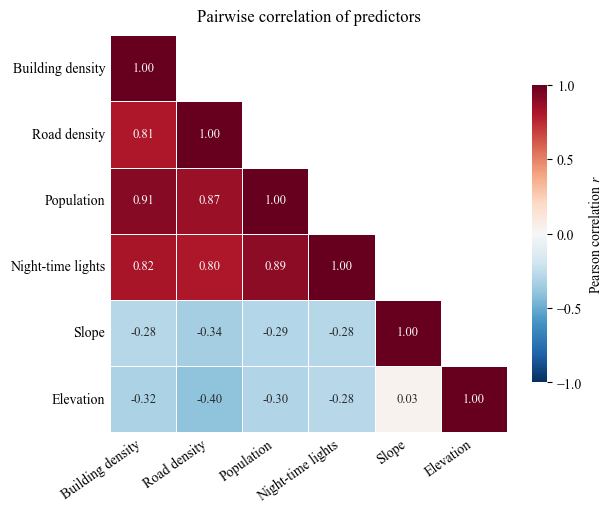

In [3]:
corr_hospital = pd.read_csv(export_dir / "hospital_predictor_correlation.csv", index_col=0)
corr_school = pd.read_csv(export_dir / "school_predictor_correlation.csv", index_col=0)

max_diff = (corr_hospital - corr_school).abs().to_numpy().max()
print(f"Largest difference between the two correlation matrices: {max_diff:.2e}")
assert max_diff < 1e-6, "Correlation matrices differ -- different training pixels?"

corr_plot = corr_hospital.rename(index=label_map, columns=label_map)

# show the lower half incl. the diagonal, hide the redundant upper half
mask = np.triu(np.ones_like(corr_plot, dtype=bool), k=1)
annot = corr_plot.round(2) + 0.0          # round and avoid "-0.00"

fig, ax = plt.subplots(figsize=(6.4, 5.2))
sns.heatmap(
    corr_plot, mask=mask,
    annot=annot, fmt=".2f", annot_kws={"size": 9},
    cmap="RdBu_r", vmin=-1, vmax=1, center=0,
    square=True, linewidths=0.6, linecolor="white",
    cbar_kws={"shrink": 0.75, "label": "Pearson correlation $r$",
              "ticks": [-1, -0.5, 0, 0.5, 1]},
    ax=ax,
)
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha="right")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title("Pairwise correlation of predictors", pad=10)
fig.tight_layout()
save_fig(fig, "predictor_correlation")
plt.show()

## 3. Precision-Recall

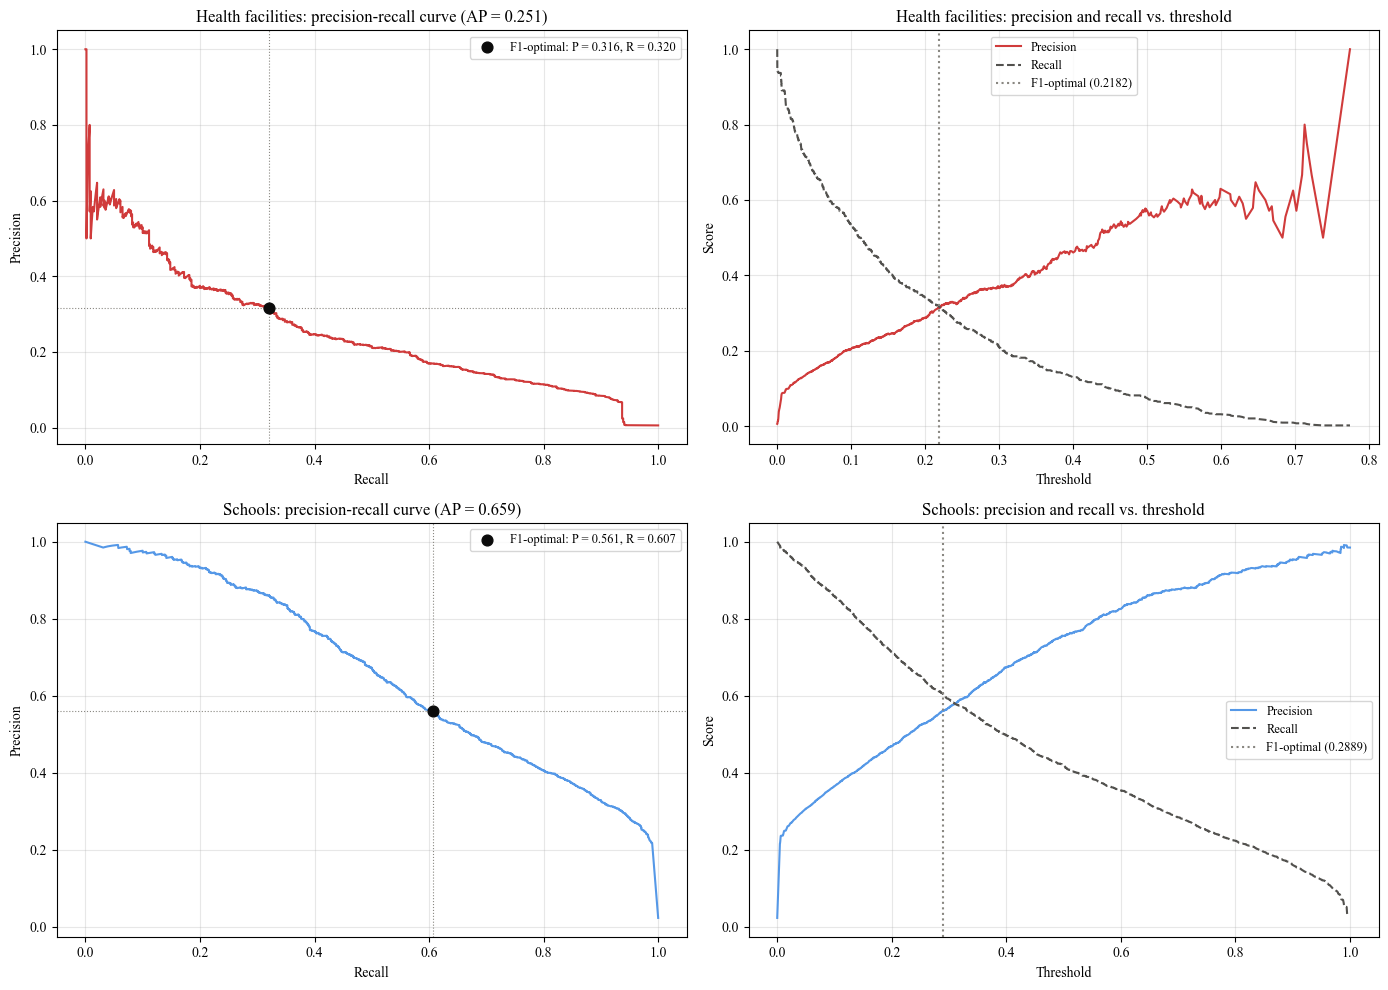

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for row, (key, m) in zip(axes, MODELS.items()):
    y_true, proba = oob[key]["y"], oob[key]["proba"]
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    ap_score = average_precision_score(y_true, proba)

    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    i_f1 = int(np.argmax(f1))
    thr_f1 = thresholds[i_f1]
    assert np.isclose(thr_f1, float(oob[key]["thr_f1"])), f"{key}: F1 threshold differs from the export"

    ax_pr, ax_thr = row

    ax_pr.plot(recall, precision, color=m["color"])
    ax_pr.scatter(recall[i_f1], precision[i_f1], color=INK, s=60, zorder=5,
                  label=f"F1-optimal: P = {precision[i_f1]:.3f}, R = {recall[i_f1]:.3f}")
    ax_pr.axhline(precision[i_f1], ls=":", color=MUTED, lw=0.8)
    ax_pr.axvline(recall[i_f1], ls=":", color=MUTED, lw=0.8)
    ax_pr.set_xlabel("Recall"); ax_pr.set_ylabel("Precision")
    ax_pr.set_title(f"{m['label']}: precision-recall curve (AP = {ap_score:.3f})")
    ax_pr.legend(loc="upper right")
    ax_pr.grid(alpha=0.3)

    ax_thr.plot(thresholds, precision[:-1], label="Precision", color=m["color"])
    ax_thr.plot(thresholds, recall[:-1], label="Recall", color=INK_SECONDARY, ls="--")
    ax_thr.axvline(thr_f1, ls=":", color=MUTED, label=f"F1-optimal ({thr_f1:.4f})")
    ax_thr.set_xlabel("Threshold"); ax_thr.set_ylabel("Score")
    ax_thr.set_title(f"{m['label']}: precision and recall vs. threshold")
    ax_thr.legend(); ax_thr.grid(alpha=0.3)

plt.tight_layout()
save_fig(fig, "precision_recall")
plt.show()

## 4. Variable Importance

 importance_mean_hospital  importance_std_hospital  importance_mean_school  importance_std_school              name  importance_mean_both
                   0.0020                   0.0000                  0.0038                 0.0000      Road density                0.0029
                   0.0054                   0.0001                  0.0022                 0.0001 Night-time lights                0.0038
                   0.0079                   0.0005                  0.0043                 0.0001             Slope                0.0061
                   0.0102                   0.0007                  0.0053                 0.0001         Elevation                0.0077
                   0.0180                   0.0003                  0.0286                 0.0004  Building density                0.0233
                   0.0612                   0.0024                  0.0232                 0.0003        Population                0.0422


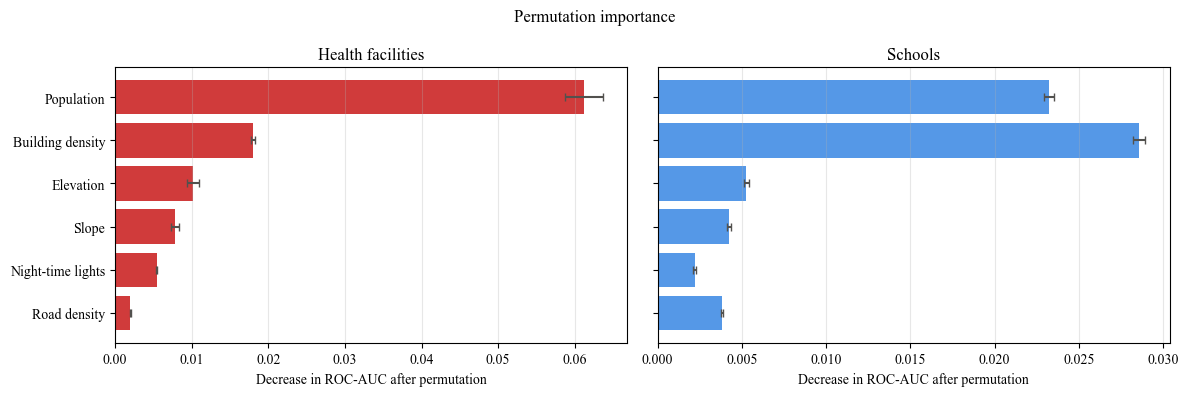

In [5]:
# one flat table: one row per predictor, models as column suffix
perm_hospital = pd.read_csv(export_dir / "hospital_perm_importance.csv")
perm_school = pd.read_csv(export_dir / "school_perm_importance.csv")
perm = perm_hospital.merge(perm_school, on="predictor", suffixes=("_hospital", "_school"))
perm["name"] = perm["predictor"].map(label_map)
perm["importance_mean_both"] = (perm["importance_mean_hospital"] + perm["importance_mean_school"]) / 2
perm = perm.sort_values("importance_mean_both")   # ascending: barh draws from bottom to top
print(perm.drop(columns="predictor").round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (key, m) in zip(axes, MODELS.items()):
    ax.barh(perm["name"], perm[f"importance_mean_{key}"],
            xerr=perm[f"importance_std_{key}"],
            color=m["color"], edgecolor="none", ecolor=INK_SECONDARY, capsize=3)
    ax.set_xlabel("Decrease in ROC-AUC after permutation")
    ax.set_title(m["label"])
    ax.grid(axis="x", alpha=0.3)
fig.suptitle("Permutation importance")

plt.tight_layout()
save_fig(fig, "permutation_importance")
plt.show()

## 5. Area of Applicability

### 5.1 Sensitivity to the cap

  cap  n_train  in_aoa_pct_hospital  in_aoa_pct_school
 1000     6735                96.23              96.28
 2000    12400                95.62              95.94
 3000    16857                95.62              95.73
 4000    20683                94.75              94.86
 5000    23683                92.62              92.59
 6000    26683                90.23              90.02
 7000    29683                86.27              86.09
 8000    32683                82.24              81.66
 9000    35435                77.57              77.70
10000    37435                74.22              73.65
20000    57435                50.14              49.06
 none    92267                41.04              41.16


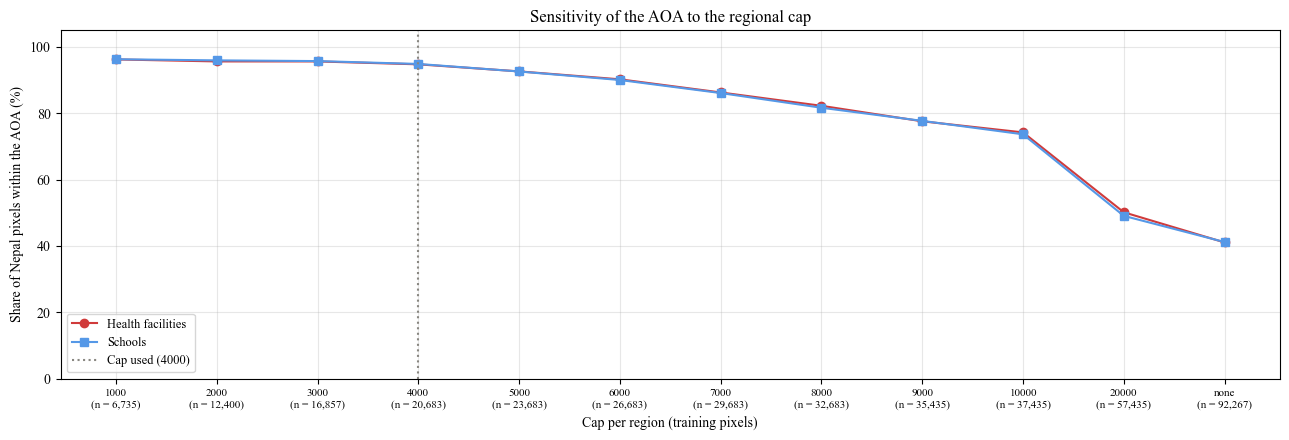

In [6]:
# one flat table: one row per cap, models as column suffix
cap_hospital = pd.read_csv(export_dir / "hospital_aoa_cap_sensitivity.csv")
cap_school = pd.read_csv(export_dir / "school_aoa_cap_sensitivity.csv")
assert cap_hospital["cap"].astype(str).tolist() == cap_school["cap"].astype(str).tolist(), \
    "The two notebooks use different cap_values"

cap = pd.DataFrame({
    "cap": cap_hospital["cap"].astype(str).replace({"unbalanciert": "none"}),
    "n_train": cap_hospital["n_train"],
    "in_aoa_pct_hospital": cap_hospital["in_aoa_pct"],
    "in_aoa_pct_school": cap_school["in_aoa_pct"],
})
print(cap.round(2).to_string(index=False))

cap_used = int(oob["hospital"]["cap_used"])
xpos = np.arange(len(cap))
i_used = cap["cap"].tolist().index(str(cap_used))

fig, ax = plt.subplots(figsize=(13, 4.5))
for key, m in MODELS.items():
    ax.plot(xpos, cap[f"in_aoa_pct_{key}"], marker=m["marker"], color=m["color"], label=m["label"])
ax.axvline(i_used, ls=":", color=MUTED, label=f"Cap used ({cap_used})")

ax.set_xticks(xpos)
ax.set_xticklabels([f"{c}\n(n = {n:,})" for c, n in zip(cap["cap"], cap["n_train"])], fontsize=8)
ax.set_xlabel("Cap per region (training pixels)")
ax.set_ylabel("Share of Nepal pixels within the AOA (%)")
ax.set_ylim(0, 105)
ax.set_title("Sensitivity of the AOA to the regional cap")
ax.grid(alpha=0.3)
ax.legend(loc="lower left")

plt.tight_layout()
save_fig(fig, "aoa_cap_sensitivity")
plt.show()

### 5.2 AOA Nepal


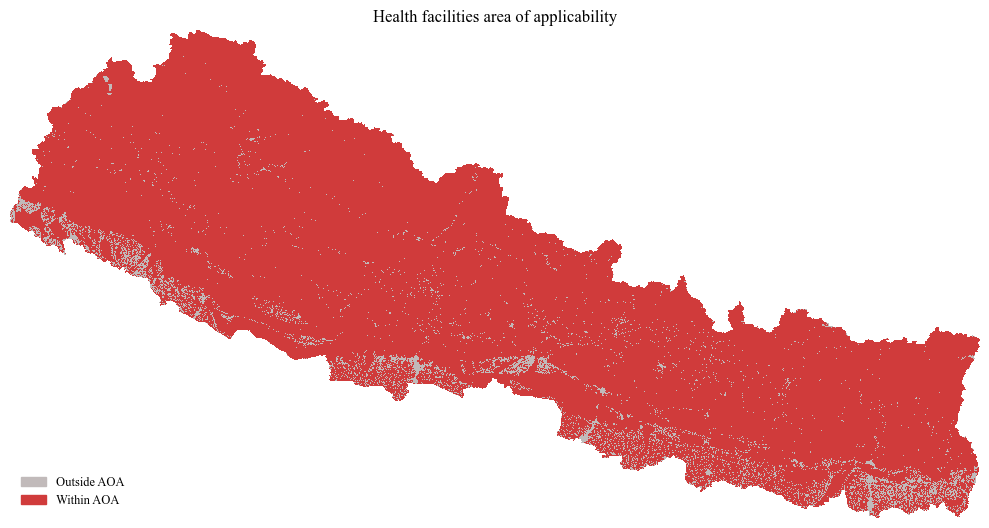

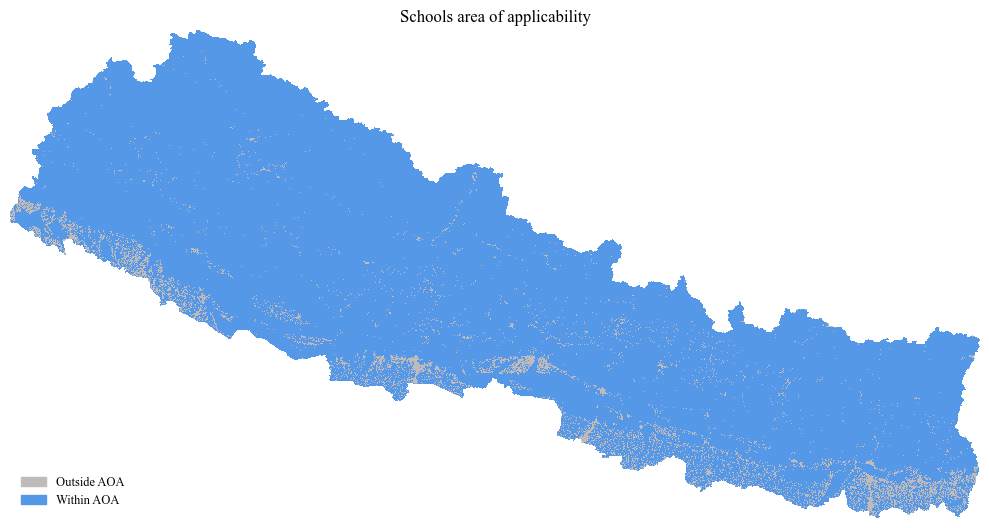

Within both AOAs: 94.1% of the valid pixels


In [7]:
aoa = {key: read_raster(m["aoa_file"]) for key, m in MODELS.items()}

for key, m in MODELS.items():
    pct = 100 * np.nanmean(aoa[key])
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.imshow(aoa[key], cmap=m["binary_cmap"], vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(f"{m['label']} area of applicability")
    ax.axis("off")
    add_binary_legend(ax, m["color"], "Outside AOA", "Within AOA")

    plt.tight_layout()
    save_fig(fig, f"aoa_nepal_{key}")
    plt.show()

both = (aoa["hospital"] == 1) & (aoa["school"] == 1)
valid = np.isfinite(aoa["hospital"]) & np.isfinite(aoa["school"])
print(f"Within both AOAs: {100 * both[valid].mean():.1f}% of the valid pixels")

## 6. Nepal-wide prediction

### 6.1 Probability

Rows: hospitals / schools. Columns: only within the AOA / all Nepal. Each row has its own colour scale (0 to the model's maximum), because the probabilities of the two models lie at different levels.

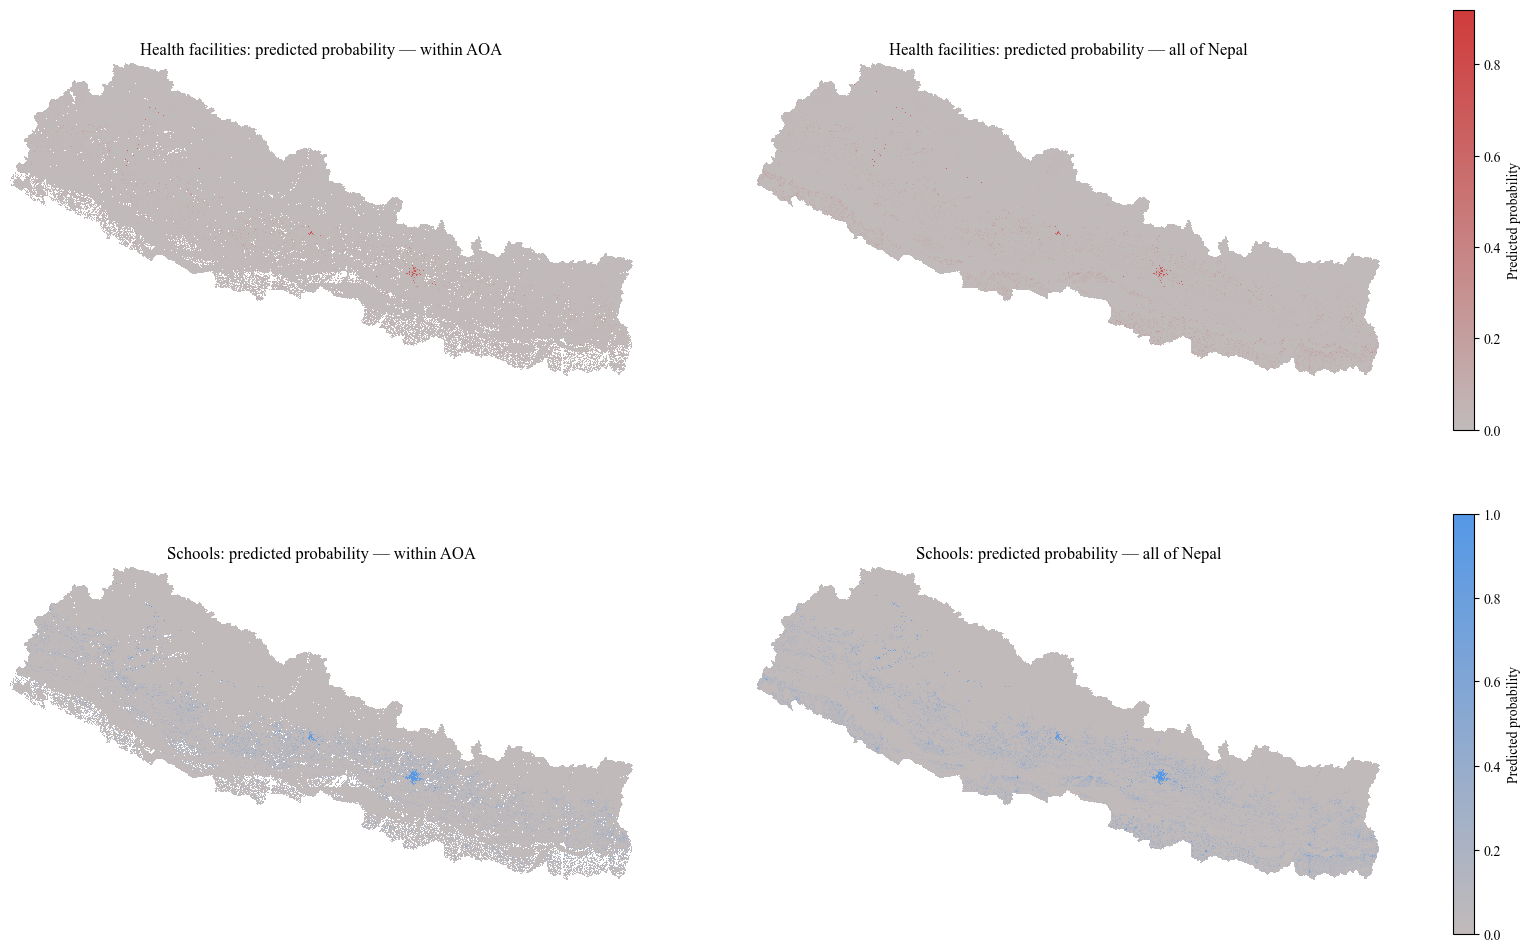

In [8]:
variants = {"aoa": "within AOA", "nepal": "all of Nepal"}

fig, axes = plt.subplots(2, 2, figsize=(19, 12))
for row, (key, m) in zip(axes, MODELS.items()):
    probs = {v: read_raster(f"{m['prob_prefix']}_{v}.tif") for v in variants}
    vmax = np.nanmax(probs["nepal"])
    for ax, (v, v_label) in zip(row, variants.items()):
        im = ax.imshow(probs[v], cmap=m["seq_cmap"], vmin=0, vmax=vmax, interpolation="nearest")
        ax.set_title(f"{m['label']}: predicted probability — {v_label}")
        ax.axis("off")
    plt.colorbar(im, ax=row, fraction=.02, label="Predicted probability")

save_fig(fig, "probability")
plt.show()

### 6.2 Candidates (F1 threshold)

Pixels with a probability above the F1-optimal threshold of the respective model.

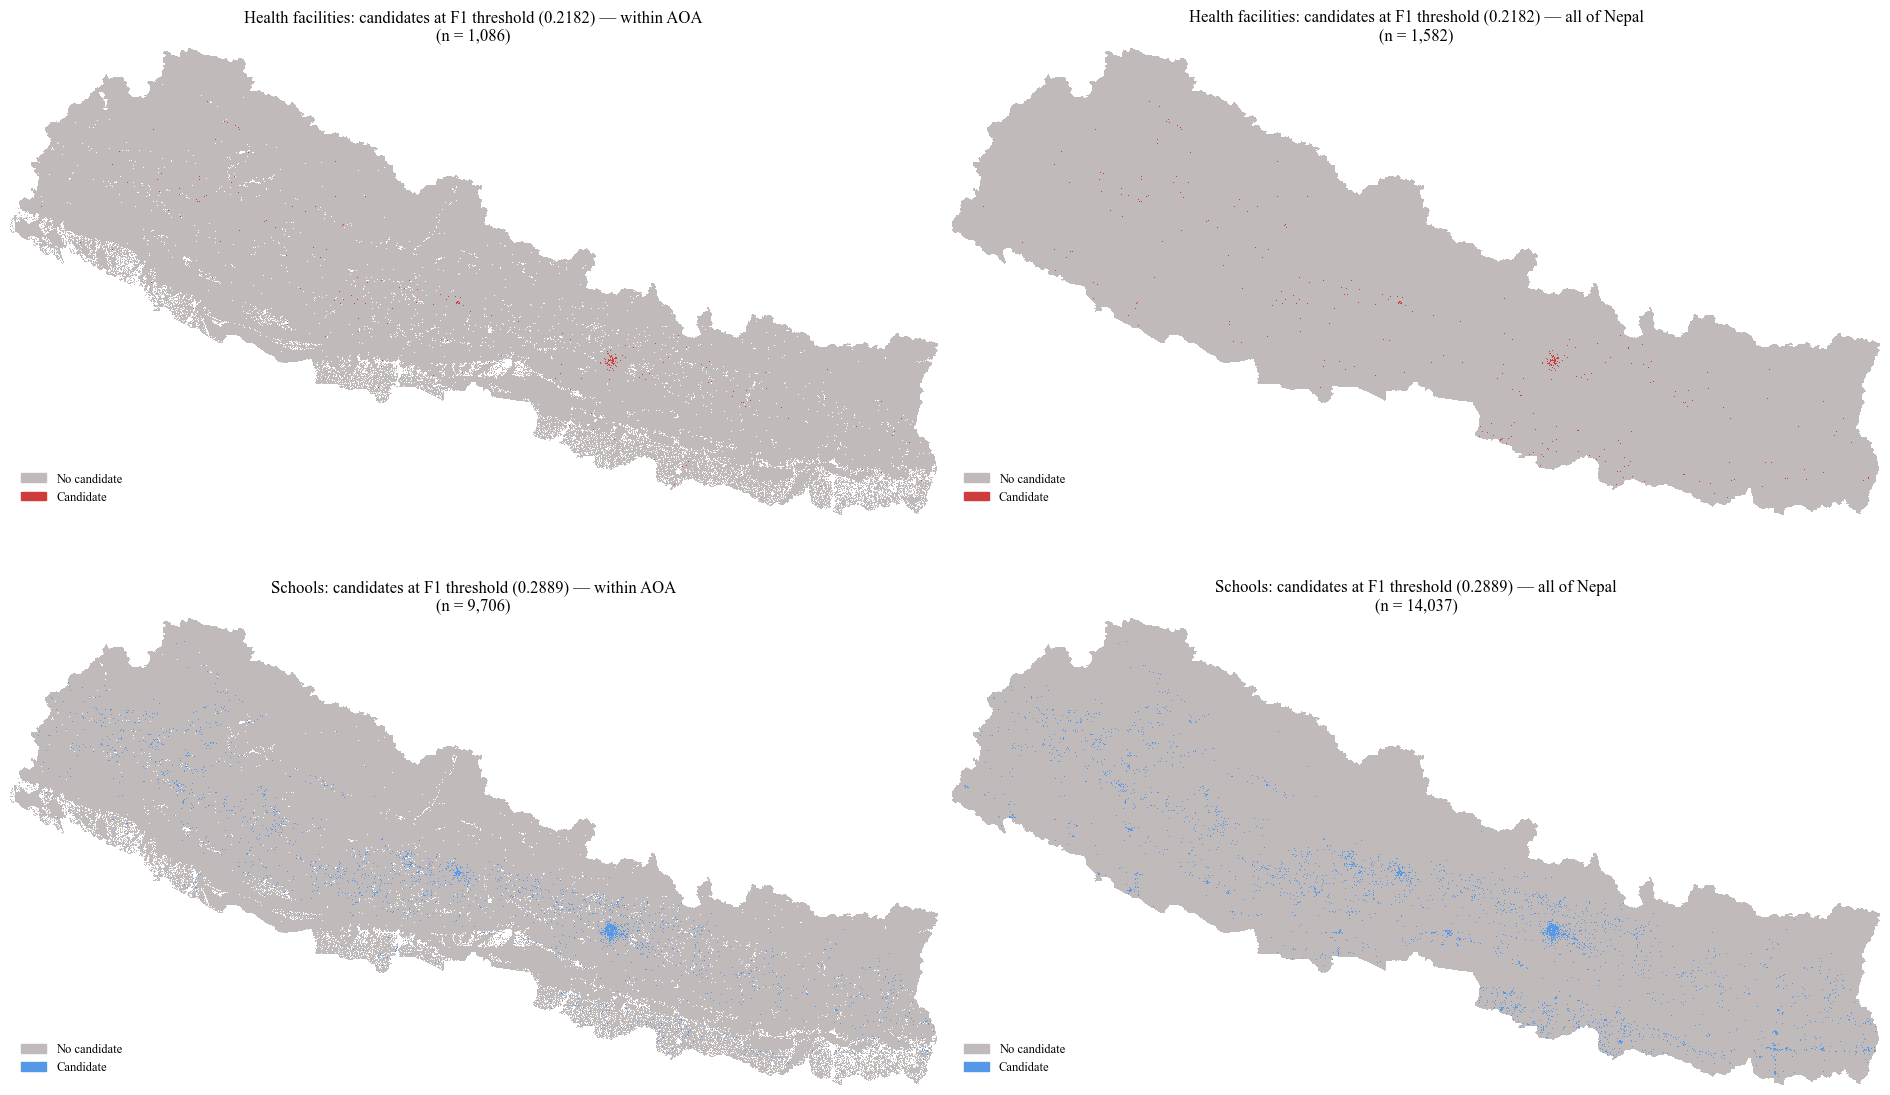

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(19, 12))
for row, (key, m) in zip(axes, MODELS.items()):
    thr = float(oob[key]["thr_f1"])
    for ax, (v, v_label) in zip(row, variants.items()):
        cand = read_raster(f"{m['cand_prefix']}_{v}.tif")
        ax.imshow(cand, cmap=m["binary_cmap"], vmin=0, vmax=1, interpolation="nearest")
        ax.set_title(f"{m['label']}: candidates at F1 threshold ({thr:.4f}) — {v_label}\n"
                     f"(n = {int(np.nansum(cand)):,})")
        ax.axis("off")
        add_binary_legend(ax, m["color"], "No candidate", "Candidate")

plt.tight_layout()
save_fig(fig, "candidates_f1")
plt.show()

### 6.3 Actual locations and prediction (without training areas)

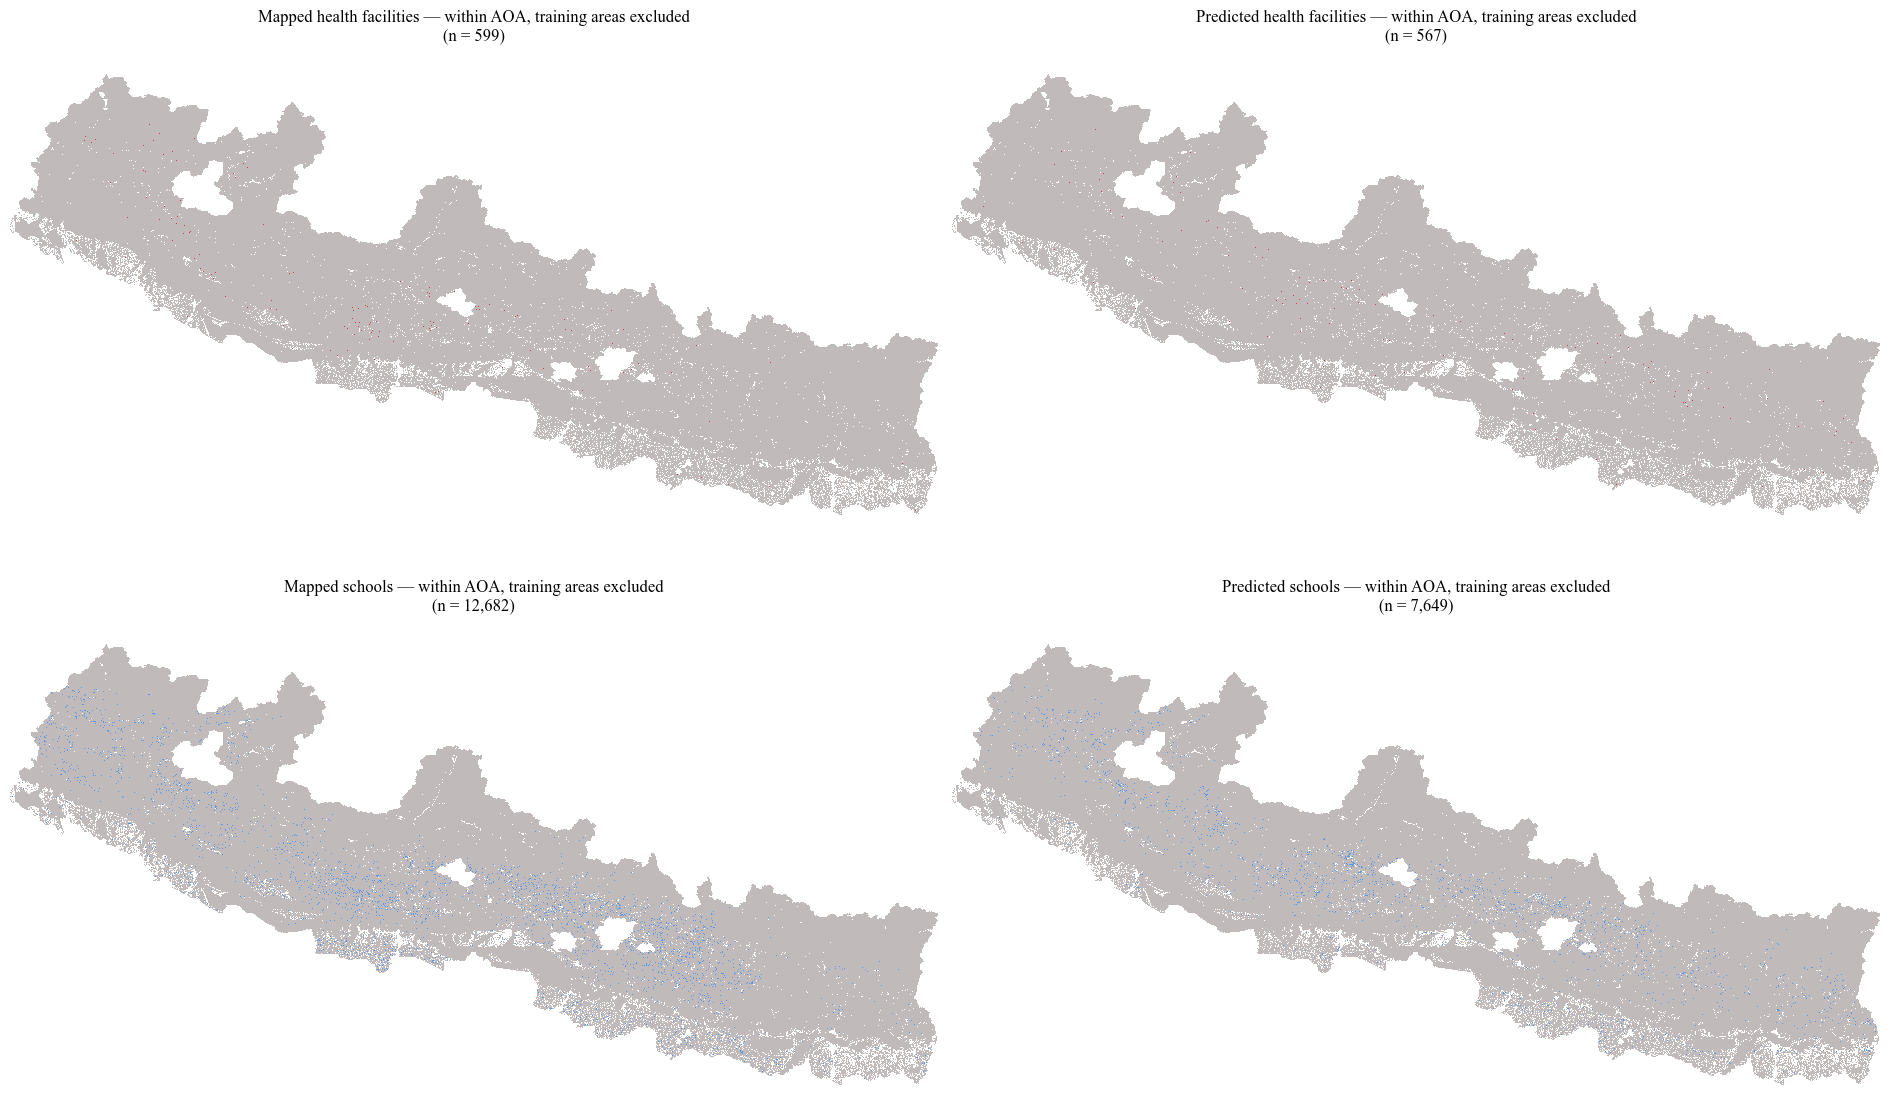

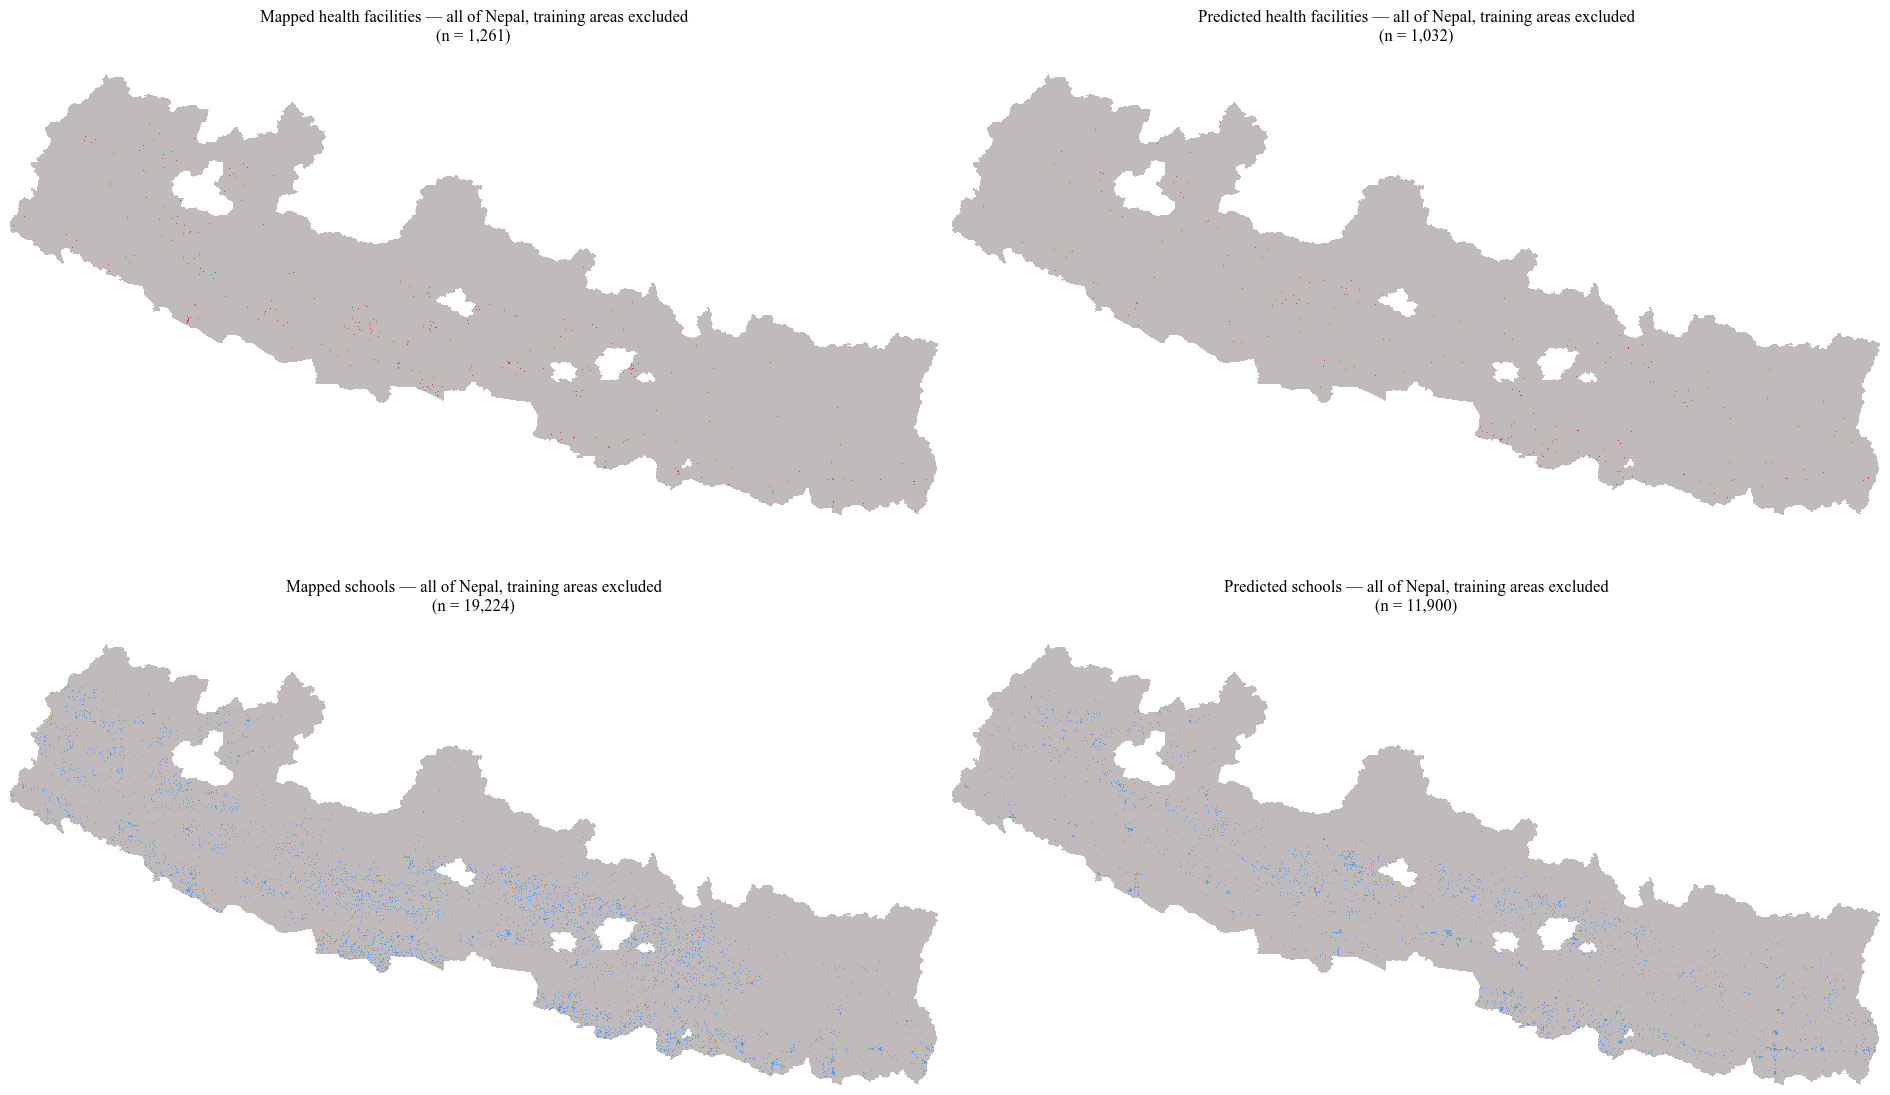

In [10]:
for v, v_label in variants.items():
    fig, axes = plt.subplots(2, 2, figsize=(19, 12))
    for row, (key, m) in zip(axes, MODELS.items()):
        layers = {
            f"Mapped {m['label'].lower()}": read_raster(f"{m['actual_prefix']}_eval_{v}.tif"),
            f"Predicted {m['label'].lower()}": read_raster(f"{m['cand_prefix']}_eval_{v}.tif"),
        }
        for ax, (title, layer) in zip(row, layers.items()):
            ax.imshow(layer, cmap=m["binary_cmap"], vmin=0, vmax=1, interpolation="nearest")
            ax.set_title(f"{title} — {v_label}, training areas excluded\n"
                         f"(n = {int(np.nansum(layer)):,})")
            ax.axis("off")
    plt.tight_layout()
    save_fig(fig, f"actual_vs_predicted_{v}")
    plt.show()